# 原生 MoE：assistant-only SFT

[English](02_moe_finetune.ipynb) | 简体中文

## Goal / 目标

训练真正的随机 tiny OLMoE，检查 router/expert 梯度、恢复 epoch checkpoint 并重载原生产物。再用 LoRA 微调 attention 与原生三维 expert 参数。合成样例只验证工程机制，不证明模型质量或大模型 GPU 适配。MoE 是 Base/Instruct 内的架构，不是新增任务。

## Setup / 环境

Kernel 需安装 `.[llm-instruct,notebooks,publish]`。下格仅在 Colab 安装。固定 SDK：Transformers 5.18.0、PEFT 0.18.1、Accelerate 1.15.0。默认 CPU/fp32，不下载模型权重，也不上传产物。真实数据、凭据与 checkpoint 不进入 Git。

In [1]:
import importlib.util
import subprocess
import sys
from pathlib import Path

try:
    IN_COLAB = importlib.util.find_spec("google.colab") is not None
except ModuleNotFoundError:
    IN_COLAB = False
if IN_COLAB:
    ROOT = Path("/content/advai-notebooks")
    if not ROOT.exists():
        subprocess.run(["git", "clone", "--depth", "1",
                        "https://github.com/advai-x/advai-notebooks.git", str(ROOT)], check=True)
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "-e",
                    f"{ROOT}[llm-instruct,notebooks,publish]"], check=True)
else:
    ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
                if (p / "pyproject.toml").is_file())
print("Repository ready; no model download requested.")

Repository ready; no model download requested.


In [2]:
import uuid
import torch
import matplotlib.pyplot as plt
from IPython.display import Markdown, display
from transformers import TrainerCallback
from transformers.utils import logging as hf_logging
from advai_notebooks.common.runtime import setup
from advai_notebooks.llm.instruct.config import load_config
from advai_notebooks.llm.instruct.data import load_data, prepare_data
from advai_notebooks.llm.instruct.model import InstructModel
from advai_notebooks.llm.instruct.pipeline import run
from advai_notebooks.llm.instruct.publish import publish
from advai_notebooks.llm.moe import describe

hf_logging.disable_progress_bar()
plt.rcParams.update({"font.family": "DejaVu Sans", "font.size": 11})
run_id = uuid.uuid4().hex[:8]
cfg = load_config(ROOT / "configs/llm/instruct/moe/smoke.yaml", ROOT)
cfg.output_dir = f"outputs/llm/instruct/moe-tutorial-{run_id}"
print({"model": cfg.model.id, "architecture": cfg.model.architecture,
       "seed": cfg.training.seed, "dtype": cfg.model.dtype})

{'model': 'tiny-olmoe', 'architecture': 'moe', 'seed': 42, 'dtype': 'float32'}


## Steps / 步骤

### 1. 校验数据并统计真实参数

任务负责文档/对话划分与监督。原生 tiny MoE 每层四个 expert，每 token 选择两个；激活 expert 较少不代表常驻权重减少。

In [3]:
rows, summary = load_data(cfg)
initial = InstructModel(cfg.model, setup(cfg), cfg.root, cfg.training, cfg.generation)
prepared = prepare_data(rows, initial, cfg)
print({"splits": summary["splits"],
       "encoded_rows": {k: len(v) for k, v in prepared.items()}})
print(describe(initial.model))
del initial, prepared

{'splits': {'train': 8, 'validation': 2, 'test': 2}, 'encoded_rows': {'train': 8, 'validation': 2, 'test': 2}}
{'model_type': 'olmoe', 'num_experts': 4, 'experts_per_token': 2, 'total_parameters': 25712, 'trainable_parameters': 25712, 'weight_bytes': 102848, 'router_trainable': True, 'aux_loss_coef': 0.01, 'parameter_dtypes': ['torch.float32'], 'note': 'Actual parameter storage, not peak training memory or active-parameter size.'}


### 2. 全参数训练，在完整 epoch 后中断并恢复

`latest` 解析到包含 optimizer、scheduler、RNG 的原生 Trainer checkpoint。Full MoE 先用原生加载器转换权重布局，再由 Trainer 恢复其余状态。推理导出不能续训；配置、数据与运行环境保持不变。

In [4]:
class StopAfterEpochOne(TrainerCallback):
    def on_save(self, args, state, control, **kwargs):
        if state.epoch >= 1:
            control.should_training_stop = True

first = run(cfg, callbacks=[StopAfterEpochOne()])
assert not first["training"]["completed"]
report = run(cfg, resume=cfg.path(cfg.output_dir) / "latest")
assert report["training"]["completed"]
audit = report["training"]["moe_gradients"]
assert audit["groups"]["router"]["nonzero_gradient_steps"] > 0
assert audit["groups"]["experts"]["nonzero_gradient_steps"] > 0
print({"selected_epoch": report["training"]["best_epoch"], "gradient_audit": audit})

{'selected_epoch': 2, 'gradient_audit': {'optimizer_steps': 4, 'groups': {'router': {'nonzero_gradient_steps': 4, 'trainable_tensors': 1, 'last_nonzero_tensors': 1, 'last_post_clip_grad_norm': 0.0065243591582636465}, 'experts': {'nonzero_gradient_steps': 4, 'trainable_tensors': 2, 'last_nonzero_tensors': 2, 'last_post_clip_grad_norm': 0.019958494270977907}, 'other': {'nonzero_gradient_steps': 4, 'trainable_tensors': 10, 'last_nonzero_tensors': 10, 'last_post_clip_grad_norm': 0.9997793381962128}}}}


### 3. 语言损失与路由诊断分开报告

验证集 NLL 选模，包含 epoch zero；test 仅报告。NLL 按移位后的监督 token 加权，PPL = exp(NLL)。原生辅助损失不计入 NLL/PPL。梯度累积采用按监督 token 加权的 microbatch 局部路由损失均值，不等同于拼接大 batch 的非线性路由损失。

In [5]:
table = "| Test diagnostic | Baseline | Selected |\n| --- | ---: | ---: |\n"
for name in ("nll", "perplexity"):
    a, b = [report[key]["metrics"][name]
            for key in ("baseline_test", "finetuned_test")]
    table += f"| {name} | {a:.4f} | {b:.4f} |\n"
a, b = [report[key]["moe"]["aux_loss"]
        for key in ("baseline_test", "finetuned_test")]
table += f"| Router auxiliary loss (not NLL) | {a:.4f} | {b:.4f} |\n"
display(Markdown(table))
print("Synthetic smoke only — this is not a quality benchmark.")

| Test diagnostic | Baseline | Selected |
| --- | ---: | ---: |
| nll | 4.7805 | 4.5240 |
| perplexity | 119.1608 | 92.2049 |
| Router auxiliary loss (not NLL) | 2.0490 | 2.0266 |


Synthetic smoke only — this is not a quality benchmark.


### 4. 检查专家使用分布

图来自选中模型的 test 报告，统计所有非 padding 输入 token（含 SFT prompt），按原生 MoE 层顺序编号。分母是 top-k 分配次数，各柱合计 100%，纵轴从零开始。虚线表示平均分配，不是质量目标；少量合成统计不构成 benchmark。

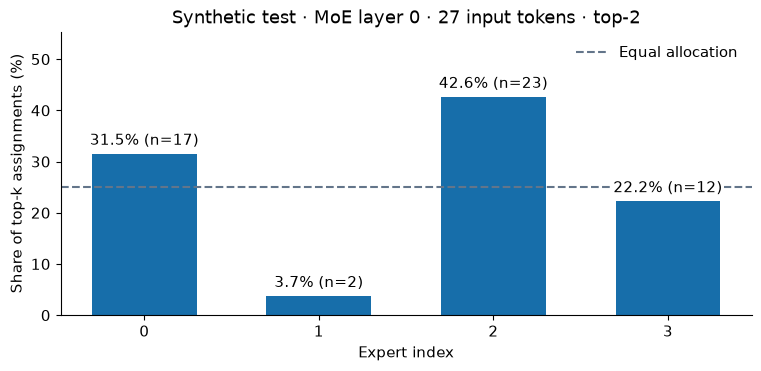

In [6]:
layer = report["finetuned_test"]["moe"]["layers"][0]
counts, shares = layer["assignment_counts"], layer["assignment_share"]
assert sum(counts) == layer["input_tokens"] * 2
assert abs(sum(shares) - 1) < 1e-8
fig, ax = plt.subplots(figsize=(7.5, 3.6), layout="constrained")
bars = ax.bar(range(len(shares)), [100 * s for s in shares], color="#176EAA", width=0.6)
ax.axhline(100 / len(shares), color="#63758A", linestyle="--", label="Equal allocation")
ax.bar_label(bars, labels=[f"{100*s:.1f}% (n={n})" for s, n in zip(shares, counts)],
             padding=4, bbox={"facecolor": "white", "edgecolor": "none", "pad": 1})
ax.set(ylim=(0, max(100 / len(shares), max(shares) * 100) * 1.3),
       xticks=range(len(shares)), xlabel="Expert index",
       ylabel="Share of top-k assignments (%)",
       title=f"Synthetic test · MoE layer 0 · {layer['input_tokens']} input tokens · top-2")
ax.spines[["top", "right"]].set_visible(False)
ax.legend(frameon=False, loc="upper right")
fig.savefig(cfg.path(cfg.output_dir) / "expert-utilization.png", dpi=140)
plt.show()

### 5. 用 LoRA 微调 attention 与三维 expert 参数

首版 LoRA 冻结 router。`target_modules` 指定 attention，`target_parameters` 指定原生 expert 张量。PEFT 0.18.1 会为这些参数 wrapper 发出通用 unsupported-layer 警告；以下检查仅证明当前 tiny 后端的梯度与合并重载一致性。真实模型长训前需重新验证。

In [7]:
adapter_cfg = load_config(ROOT / "configs/llm/instruct/moe/smoke_experts_lora.yaml", ROOT)
adapter_cfg.output_dir = f"outputs/llm/instruct/moe-experts-tutorial-{run_id}"
adapter_report = run(adapter_cfg)
adapter_audit = adapter_report["training"]["moe_gradients"]["groups"]
assert adapter_audit["router"]["trainable_tensors"] == 0
assert adapter_audit["experts"]["nonzero_gradient_steps"] > 0
assert adapter_audit["other"]["nonzero_gradient_steps"] > 0
print(adapter_audit)

/Users/xuyi/Documents/workspace/advai-notebooks/.venv-regression/lib/python3.12/site-packages/peft/tuners/tuners_utils.py:212: UserWarning: Unsupported layer type '<class 'transformers.models.olmoe.modeling_olmoe.OlmoeExperts'>' encountered, proceed at your own risk.
  warnings.warn(f"Unsupported layer type '{type(module)}' encountered, proceed at your own risk.", UserWarning)


{'router': {'nonzero_gradient_steps': 0, 'trainable_tensors': 0, 'last_nonzero_tensors': 0, 'last_post_clip_grad_norm': 0.0}, 'experts': {'nonzero_gradient_steps': 4, 'trainable_tensors': 4, 'last_nonzero_tensors': 4, 'last_post_clip_grad_norm': 0.01486894339666207}, 'other': {'nonzero_gradient_steps': 4, 'trainable_tensors': 4, 'last_nonzero_tensors': 4, 'last_post_clip_grad_norm': 0.2784292877743711}}


/Users/xuyi/Documents/workspace/advai-notebooks/.venv-regression/lib/python3.12/site-packages/peft/tuners/tuners_utils.py:212: UserWarning: Unsupported layer type '<class 'transformers.models.olmoe.modeling_olmoe.OlmoeExperts'>' encountered, proceed at your own risk.
  warnings.warn(f"Unsupported layer type '{type(module)}' encountered, proceed at your own risk.", UserWarning)


## Checks / 检查

重载 adapter、合并副本、对比 logits 与贪心生成，并离线预览发布。验证产物契约，不评价回答质量；只有 adapter 更新，原始 base 权重保持冻结。

In [8]:
adapter = InstructModel.load(adapter_report["export"])
merged_path = adapter.save(adapter_cfg.path(adapter_cfg.output_dir) / "merged", merged=True)
merged = InstructModel.load(merged_path)
batch = adapter.tokenizer("the sky is blue", return_tensors="pt")
adapter.model.eval()
merged.model.eval()
with torch.no_grad():
    torch.testing.assert_close(adapter.model(**batch).logits,
                               merged.model(**batch).logits, rtol=1e-5, atol=1e-5)
plan = publish(adapter_report["export"], "example/moe-instruct-smoke", dry_run=True)
names = {item["path"] for item in plan["files"]}
assert "adapter_model.safetensors" in names
assert not names & {"optimizer.pt", "rng_state.pth", "raw-data.jsonl", ".env"}
print({"native_merge_equal": True, "publication": plan["status"], "files": len(names)})

{'native_merge_equal': True, 'publication': 'dry_run', 'files': 11}


In [9]:
messages = [{"role": "user", "content": "what color is the sky ?"}]
result = adapter.chat(messages, max_new_tokens=3)
assert result == merged.chat(messages, max_new_tokens=3)
print({"synthetic_reply": result})

{'synthetic_reply': ''}


## Next Steps / 下一步

阅读 [MoE 指南](../../../docs/llm-moe.zh-CN.md)。用 `smoke_qwen3.yaml` 检查另一原生后端，或用 `smoke_lora.yaml` 仅适配 attention。真实训练将 `olmoe_lora.yaml` / `qwen3_lora.yaml` 复制到被忽略的 `configs/local/`，替换数据与输出路径，并核查固定版本的模型、tokenizer 和许可证。Qwen Instruct 配置有意使用显式纯文本 non-thinking 模板。所有专家权重仍常驻（bf16 仅权重约 OLMoE 14 GB / Qwen3 61 GB，另需训练内存）。预算检查只是下限防护，不保证能跑。这里未验证真实 GPU 训练、AMP 恢复或领域质量，不含 QLoRA、expert parallel 或 MoE PPO/GRPO；Colab checkpoint 应持久化，免费 Colab 不保证适配。